# Módulo 5 — Integral definida y área bajo la curva (prototipo en Python)

**Proyecto:** Cálculo Integral Interactivo · Matemáticas II · UTP

Aquí comprobamos numéricamente el **Teorema Fundamental del Cálculo**, la diferencia entre *integral con signo* y *área*, y el área entre curvas. Los algoritmos numéricos van escritos con NumPy; SymPy solo aporta antiderivadas y valores exactos.

## 1. Preparación

In [1]:
# --- Bibliotecas que usaremos ---
import numpy as np                 # cálculo numérico con arreglos
import matplotlib.pyplot as plt    # gráficas
import sympy as sp                 # matemática simbólica: SOLO para el valor exacto y para verificar
                                   # (los algoritmos numéricos los escribimos nosotros desde cero)

x = sp.symbols("x")                # símbolo matemático "x" para SymPy

def preparar(expr, a, b):
    """Convierte una expresión de SymPy en (f_numpy, valor_exacto).
    - f_numpy: función que acepta arreglos de NumPy.
    - valor_exacto: integral definida exacta (Teorema Fundamental del Cálculo), como número decimal."""
    f = sp.lambdify(x, expr, "numpy")
    exacto = float(sp.integrate(expr, (x, a, b)))
    return f, exacto


def simpson(f, a, b, n=2000):
    """Regla de Simpson (módulo 4), con muchos subintervalos para tener buena precisión."""
    if n % 2: n += 1
    xs = np.linspace(a, b, n + 1)
    coef = np.ones(n + 1); coef[1:-1:2] = 4; coef[2:-1:2] = 2
    return (b - a) / n / 3 * np.sum(coef * f(xs))

## 2. Teorema Fundamental del Cálculo (Parte 2)

Si $F'=f$, entonces $\displaystyle\int_a^b f(x)\,dx=F(b)-F(a)$.

**Ejemplo 1 del módulo:** $\displaystyle\int_1^3 (3x^2-2x)\,dx$.

In [2]:
expr = 3 * x**2 - 2 * x
F_manual = x**3 - x**2                       # la antiderivada que encontramos a mano

# 1) Verificamos por derivación que F' = f
assert sp.simplify(sp.diff(F_manual, x) - expr) == 0
print("✔ F'(x) = f(x)")

# 2) Evaluamos F(b) - F(a)
F = sp.lambdify(x, F_manual, "numpy")
print("F(3) - F(1) =", F(3) - F(1), "  (a mano: 18)")

# 3) Comparamos con la aproximación numérica de Simpson
f = sp.lambdify(x, expr, "numpy")
print("Simpson (n=2000) =", round(simpson(f, 1, 3), 8))
assert np.isclose(F(3) - F(1), 18)

✔ F'(x) = f(x)
F(3) - F(1) = 18   (a mano: 18)
Simpson (n=2000) = 18.0


## 3. Teorema Fundamental (Parte 1): la función de acumulación

$A(t)=\displaystyle\int_a^t f(u)\,du$ cumple $A'(t)=f(t)$. Lo comprobamos así:

1. Construimos $A$ **numéricamente** acumulando áreas de trapecios pequeños.
2. La comparamos con la fórmula exacta $F(t)-F(a)$.
3. Derivamos $A$ numéricamente y comprobamos que se parece a $f$.

Máxima diferencia |A(t) - (sen t - sen 0)| = 8.224671689260887e-07
Máxima diferencia |A'(t) - cos t| (sin los bordes) = 2.467399079275623e-06


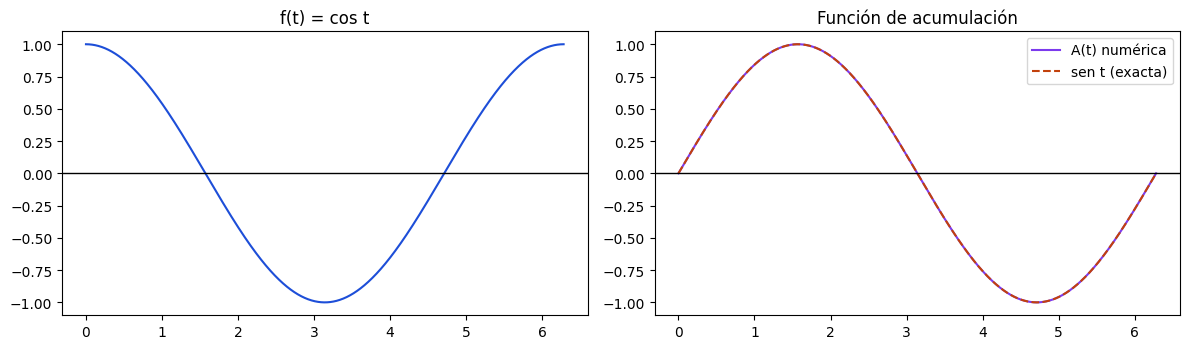

In [3]:
def acumulada(f, a, b, n=2000):
    """Devuelve (t, A) donde A[k] ≈ integral de f desde a hasta t[k]. Suma acumulada de trapecios."""
    t = np.linspace(a, b, n + 1)
    y = f(t)
    dt = (b - a) / n
    aportes = (y[1:] + y[:-1]) / 2 * dt              # área de cada trapecio pequeño
    A = np.concatenate([[0.0], np.cumsum(aportes)])  # suma acumulada (empieza en 0)
    return t, A

# Usamos f(x) = cos(x) en [0, 2π]; su antiderivada es sen(x)
f = sp.lambdify(x, sp.cos(x), "numpy")
t, A = acumulada(f, 0, 2 * np.pi)

print("Máxima diferencia |A(t) - (sen t - sen 0)| =", np.max(np.abs(A - np.sin(t))))

dA = np.gradient(A, t)                               # derivada numérica de A
print("Máxima diferencia |A'(t) - cos t| (sin los bordes) =", np.max(np.abs(dA[1:-1] - f(t[1:-1]))))

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.6))
ejes[0].plot(t, f(t), color="#1d4ed8"); ejes[0].set_title("f(t) = cos t"); ejes[0].axhline(0, color="k", lw=1)
ejes[1].plot(t, A, color="#7c3aed", label="A(t) numérica")
ejes[1].plot(t, np.sin(t), "--", color="#c2410c", label="sen t (exacta)")
ejes[1].set_title("Función de acumulación"); ejes[1].legend(); ejes[1].axhline(0, color="k", lw=1)
plt.tight_layout(); plt.show()

## 4. Integral con signo frente a área

**Ejemplo 2 del módulo:** $f(x)=\operatorname{sen}(x)$ en $[0,2\pi]$.

In [4]:
expr = sp.sin(x)
f = sp.lambdify(x, expr, "numpy")
a, b = 0.0, 2 * np.pi

integral = float(sp.integrate(expr, (x, 0, 2 * sp.pi)))        # con signo, exacta
area_num = simpson(lambda z: np.abs(f(z)), a, b)               # área: integramos |f|

# Área "a mano": partimos en el cambio de signo x = π y sumamos valores absolutos
cortes = [0, sp.pi, 2 * sp.pi]
area_tramos = sum(abs(float(sp.integrate(expr, (x, c0, c1)))) for c0, c1 in zip(cortes[:-1], cortes[1:]))

print(f"Integral con signo  = {integral:.6f}   (a mano: 0)")
print(f"Área (Simpson |f|)  = {area_num:.6f}")
print(f"Área (por tramos)   = {area_tramos:.6f}   (a mano: 4)")
assert abs(integral) < 1e-12 and np.isclose(area_tramos, 4) and np.isclose(area_num, 4, atol=1e-6)
print("✔ Integral = 0 pero área = 4")

Integral con signo  = 0.000000   (a mano: 0)
Área (Simpson |f|)  = 4.000000
Área (por tramos)   = 4.000000   (a mano: 4)
✔ Integral = 0 pero área = 4


## 5. Área entre curvas

**Ejemplo 3 del módulo:** región encerrada entre $y=\sqrt{x}$ y $y=x^2$.

In [5]:
f_sup = sp.sqrt(x)
g_inf = x**2

# Puntos de corte: resolvemos f(x) = g(x)
cortes = sp.solve(sp.Eq(f_sup, g_inf), x)
print("Soluciones que devuelve SymPy:", cortes)

Soluciones que devuelve SymPy: [0, 1]


SymPy puede devolver soluciones que no nos sirven (por ejemplo complejas). Nos quedamos solo con las **reales**:

Puntos de corte reales: [0.0, 1.0]
Área exacta = 0.333333333333333 = 0.3333333333333333   (a mano: 1/3)
Área numérica = 0.33333243
✔ Coincide con el ejemplo 3 del módulo 5


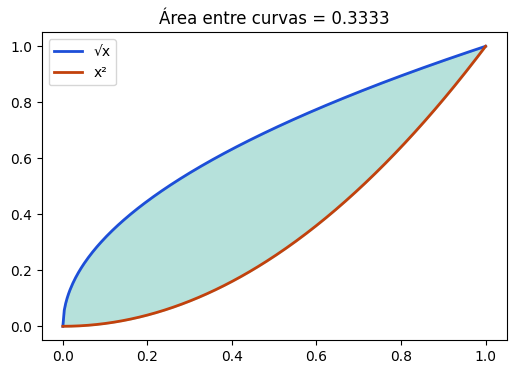

In [6]:
cortes_reales = sorted(float(c) for c in cortes if c.is_real)
a, b = cortes_reales[0], cortes_reales[-1]
print("Puntos de corte reales:", cortes_reales)

# Área exacta: integral de (arriba - abajo)
area_exacta = sp.integrate(f_sup - g_inf, (x, a, b))
print("Área exacta =", area_exacta, "=", float(area_exacta), "  (a mano: 1/3)")

# Área numérica con |f - g| (sirve aunque las curvas se crucen)
f_n = sp.lambdify(x, f_sup, "numpy"); g_n = sp.lambdify(x, g_inf, "numpy")
area_num = simpson(lambda z: np.abs(f_n(z) - g_n(z)), a, b)
print(f"Área numérica = {area_num:.8f}")
assert np.isclose(float(area_exacta), 1 / 3) and np.isclose(area_num, 1 / 3, atol=1e-6)
print("✔ Coincide con el ejemplo 3 del módulo 5")

xs = np.linspace(a, b, 300)
plt.figure(figsize=(6, 4))
plt.plot(xs, f_n(xs), label="√x", color="#1d4ed8", lw=2)
plt.plot(xs, g_n(xs), label="x²", color="#c2410c", lw=2)
plt.fill_between(xs, g_n(xs), f_n(xs), alpha=0.3, color="#0f9d8a")
plt.legend(); plt.title(f"Área entre curvas = {float(area_exacta):.4f}"); plt.show()

## Preguntas para pensar

1. En la sección 3, ¿por qué la derivada numérica coincide con $\cos t$ salvo pequeños errores? ¿Qué pasa en los bordes del intervalo y por qué los excluimos?
2. Si `simpson` integra $|f|$ pero $|f|$ tiene una "esquina" en el cruce por cero, ¿por qué el resultado sigue siendo muy bueno con $n=2000$, aunque no exacto? (Compara `area_num` con `area_tramos` con más decimales.)
3. **Ejercicio:** calcula el área entre $y=x$ y $y=x^2$. Primero halla los cortes a mano y luego verifica con este cuaderno. (En el visualizador, elige $f(x)=x$ y $g(x)=x^2$.)